# Uçuş Gecikmesi Tahmini — 5. Son model ve demo dosyaları
Bu notebook **bir kez** çalıştırılır:
1. **Son model:** Model seçimi ve test ölçümü 4. notebook'ta bitti. Şimdi aynı ayarlarla, aynı ağaç sayısıyla, **2025'in tamamıyla** yeniden eğitiyoruz.
   (Standart uygulama: değerlendirme ayrılmış test setiyle yapılır; kullanıma çıkacak model ise elimizdeki tüm veriyle eğitilir.
   Böylece model Kasım–Aralık gibi eğitimde görmediği dönemleri de öğrenir ve olasılıkları gerçeğe yaklaşır.)
2. **Değişken önemi grafiğini** düzeltilmiş başlıkla yeniden çiziyoruz.
3. **Demo dosyaları:** Streamlit uygulamasının ihtiyaç duyduğu küçük tabloları `UcusGecikme/app/assets/` klasörüne kaydediyoruz
   (rotalar, havalimanları, günlük hava durumu, tarife yoğunlukları, model).

Çalışma zamanı → Tümünü çalıştır (10–15 dakika). Bitince .ipynb olarak indirip gönder.

## 0. Kurulum

In [1]:
import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'duckdb', 'lightgbm'], check=False)

import json
import shutil
import time
import warnings
from pathlib import Path

import duckdb
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/UcusGecikme')
except ImportError:
    BASE = Path('.')
DATA = BASE / 'processed' / 'flights_2025_clean.parquet'
MODELS, FIG = BASE / 'models', BASE / 'figures'
ASSETS = BASE / 'app' / 'assets'
ASSETS.mkdir(parents=True, exist_ok=True)
meta_old = json.loads((MODELS / 'model_meta.json').read_text())
FEATURES, CAT = meta_old['features'], meta_old['categorical']
TARGET = 'target_arr_del15'
con = duckdb.connect()
print('Değişken sayısı:', len(FEATURES))

Mounted at /content/drive
Değişken sayısı: 41


## 1. Son model: 2025'in tamamıyla yeniden eğitim

In [2]:
t0 = time.time()
df = con.sql(f'''
    SELECT month, {', '.join(c for c in FEATURES if c != 'dep_minute')},
           (crs_dep_hhmm // 100) * 60 + (crs_dep_hhmm % 100) AS dep_minute, {TARGET}
    FROM '{DATA}'
    WHERE status = 'tamamlandi' AND {TARGET} IS NOT NULL AND crs_elapsed_min > 0 AND crs_dep_hhmm IS NOT NULL''').df()
for c in df.columns:
    if c in CAT or c in (TARGET, 'month'):
        continue
    df[c] = df[c].astype('float32')
for c in CAT:
    df[c] = pd.Categorical(df[c], categories=sorted(df[c].dropna().unique()))
print(f'{len(df):,} uçuş yüklendi ({time.time() - t0:.0f} sn)')

old = lgb.Booster(model_file=str(MODELS / 'lgbm_delay.txt'))
n_rounds = int(round(old.num_trees() * 1.1))  # %10 daha fazla veri → %10 daha fazla ağaç (yaygın kural)
PARAMS = dict(objective='binary', learning_rate=0.1, num_leaves=127, min_data_in_leaf=500, feature_fraction=0.8,
              bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0, cat_smooth=50, max_cat_to_onehot=8,
              seed=42, verbose=-1, num_threads=0)
t0 = time.time()
final = lgb.train(PARAMS, lgb.Dataset(df[FEATURES], df[TARGET].values, categorical_feature=CAT), num_boost_round=n_rounds)
print(f'Son model: {n_rounds} ağaç, {time.time() - t0:.0f} sn')

p_all = final.predict(df[FEATURES])
print(f'Gerçek gecikme oranı: %{df[TARGET].mean() * 100:.1f}   Modelin ortalama tahmini: %{p_all.mean() * 100:.1f}')
df['p'] = p_all
cal = df.groupby('month').agg(gercek=(TARGET, 'mean'), tahmin=('p', 'mean')) * 100
print('\nAylara göre gerçek ve tahmin edilen ortalama gecikme oranı (%) — kalibrasyon kontrolü:')
print(cal.round(1).to_string())

final.save_model(str(MODELS / 'lgbm_final.txt'))
meta = dict(meta_old)
meta.update({'categories': {c: list(map(str, df[c].cat.categories)) for c in CAT}, 'n_rounds_final': n_rounds,
             'final_trained_on': '2025-01..2025-12 (tüm tamamlanan uçuşlar)', 'base_rate_all': float(df[TARGET].mean())})
(MODELS / 'model_meta_final.json').write_text(json.dumps(meta, ensure_ascii=False, indent=1))
print('\nKaydedildi: models/lgbm_final.txt, models/model_meta_final.json')

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

6,879,483 uçuş yüklendi (32 sn)
Son model: 227 ağaç, 413 sn
Gerçek gecikme oranı: %22.3   Modelin ortalama tahmini: %22.3

Aylara göre gerçek ve tahmin edilen ortalama gecikme oranı (%) — kalibrasyon kontrolü:
       gercek  tahmin
month                
1        18.8    19.9
2        20.8    21.3
3        19.6    19.9
4        19.7    19.9
5        23.6    23.1
6        28.3    27.6
7        28.9    28.1
8        22.6    22.7
9        16.6    18.1
10       20.3    20.1
11       20.6    21.1
12       26.8    24.9

Kaydedildi: models/lgbm_final.txt, models/model_meta_final.json


## 2. Değişken önemi grafiği (düzeltilmiş)
Değerlendirme modelinin (4. notebook) test setindeki SHAP katkılarıyla, başlık–alt başlık çakışması düzeltilmiş olarak.

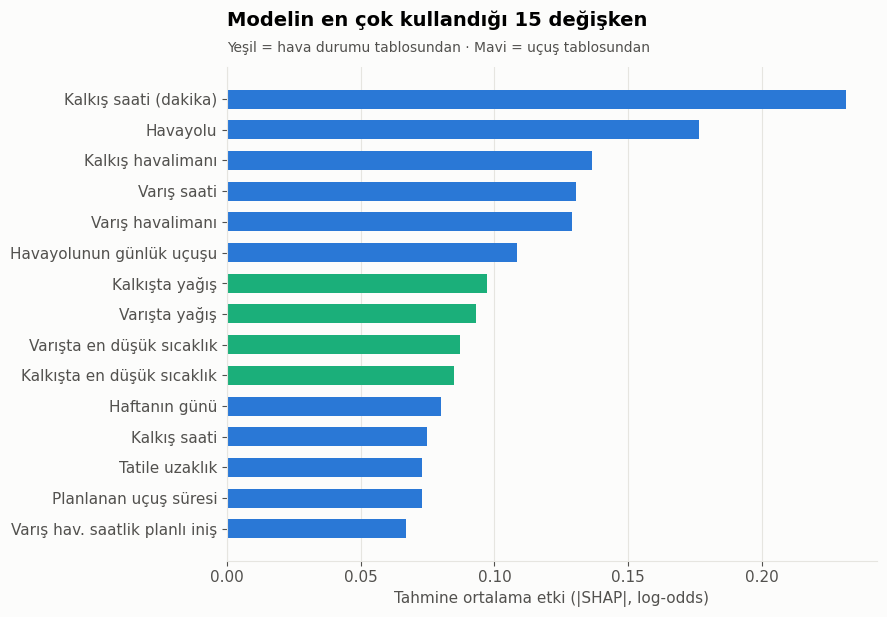

Kaydedildi: figures/13_degisken_onemi.png


In [3]:
BLUE, AQUA, INK, INK2, GRID, SURFACE = '#2a78d6', '#1baf7a', '#0b0b0b', '#52514e', '#e6e5e0', '#fcfcfb'
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
                     'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID,
                     'font.size': 11, 'axes.titlesize': 14, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left'})
te = df[df['month'].isin(meta_old['test_months'])]
te = te.sample(min(50_000, len(te)), random_state=42)
contrib = old.predict(te[FEATURES], pred_contrib=True)
imp = pd.Series(np.abs(contrib[:, :-1]).mean(axis=0), index=FEATURES).sort_values(ascending=False)
WXN = {'tmax_c': 'en yüksek sıcaklık', 'tmin_c': 'en düşük sıcaklık', 'prcp_mm': 'yağış', 'snow_mm': 'kar', 'snwd_mm': 'yerdeki kar',
       'awnd_ms': 'ortalama rüzgar', 'wsf2_ms': 'en sert rüzgar', 'fog': 'sis', 'thunder': 'fırtına', 'hail': 'dolu',
       'freezing': 'don', 'heavy_rain': 'yoğun yağış', 'snow_day': 'kar günü'}
NAMES = {'dep_minute': 'Kalkış saati (dakika)', 'dep_hour': 'Kalkış saati', 'arr_hour': 'Varış saati', 'airline': 'Havayolu',
         'origin': 'Kalkış havalimanı', 'dest': 'Varış havalimanı', 'day_of_week': 'Haftanın günü',
         'origin_sched_dep_day': 'Kalkış hav. günlük planlı uçuş', 'origin_sched_dep_hour': 'Kalkış hav. saatlik planlı uçuş',
         'dest_sched_arr_hour': 'Varış hav. saatlik planlı iniş', 'airline_sched_day': 'Havayolunun günlük uçuşu',
         'days_to_holiday': 'Tatile uzaklık', 'is_holiday': 'Tatil günü', 'crs_elapsed_min': 'Planlanan uçuş süresi', 'distance_mi': 'Mesafe'}
NAMES.update({f'o_{k}': f'Kalkışta {v}' for k, v in WXN.items()})
NAMES.update({f'd_{k}': f'Varışta {v}' for k, v in WXN.items()})
top = imp.head(15)[::-1]
fig, ax = plt.subplots(figsize=(9, 6.3))
ax.barh([NAMES.get(i, i) for i in top.index], top.values, height=0.62,
        color=[AQUA if i.startswith(('o_', 'd_')) else BLUE for i in top.index], zorder=2)
ax.grid(axis='y', visible=False)
ax.set_xlabel('Tahmine ortalama etki (|SHAP|, log-odds)')
ax.set_title('Modelin en çok kullandığı 15 değişken', pad=30)
ax.text(0, 1.03, 'Yeşil = hava durumu tablosundan · Mavi = uçuş tablosundan', transform=ax.transAxes, color=INK2, fontsize=10)
fig.tight_layout()
fig.savefig(FIG / '13_degisken_onemi.png', dpi=200, bbox_inches='tight')
plt.show()
print('Kaydedildi: figures/13_degisken_onemi.png')

## 3. Demo dosyaları
Uygulama 7 milyon satırı taşımaz; sadece tahmin için gereken küçük özet tabloları kullanır.

In [4]:
del df, p_all
src = f"(SELECT * FROM '{DATA}')"
tables = {
    # Rota tablosu: havayolu + kalkış + varış → tipik süre, mesafe, varış saati farkı, 2025 gecikme oranı
    'routes': f'''SELECT airline, origin, dest, count(*) AS n,
                         avg(target_arr_del15) FILTER (WHERE status = 'tamamlandi') AS delay_rate,
                         median(crs_elapsed_min) AS crs_elapsed_min, median(distance_mi) AS distance_mi,
                         median(((crs_arr_hhmm // 100) * 60 + crs_arr_hhmm % 100 - ((crs_dep_hhmm // 100) * 60 + crs_dep_hhmm % 100) + 1440) % 1440) AS arr_offset_min
                  FROM {src} WHERE crs_elapsed_min > 0 GROUP BY ALL HAVING count(*) >= 20''',
    # Tarife yoğunlukları (uçuştan önce bilinir)
    'sched_origin_hour': f'SELECT origin, flight_date, dep_hour, count(*) AS n FROM {src} GROUP BY ALL',
    'sched_origin_day': f'SELECT origin, flight_date, count(*) AS n FROM {src} GROUP BY ALL',
    'sched_dest_hour': f'SELECT dest, flight_date, arr_hour, count(*) AS n FROM {src} GROUP BY ALL',
    'sched_airline_day': f'SELECT airline, flight_date, count(*) AS n FROM {src} GROUP BY ALL',
}
for name, q in tables.items():
    con.sql(f"COPY ({q}) TO '{ASSETS / (name + '.parquet')}' (FORMAT parquet, COMPRESSION zstd)")

aps = pd.read_parquet(BASE / 'processed' / 'airports.parquet')[['code', 'city', 'state', 'ap_name', 'lat', 'lon']]
aps.to_parquet(ASSETS / 'airports.parquet', index=False)
shutil.copy(BASE / 'processed' / 'weather_daily_2025.parquet', ASSETS / 'weather.parquet')
shutil.copy(MODELS / 'lgbm_final.txt', ASSETS / 'lgbm_final.txt')
shutil.copy(MODELS / 'model_meta_final.json', ASSETS / 'model_meta_final.json')

total = 0
for f in sorted(ASSETS.iterdir()):
    total += f.stat().st_size
    print(f'  {f.name:32s} {f.stat().st_size / 1e6:6.1f} MB')
print(f'Toplam: {total / 1e6:.1f} MB')
r = pd.read_parquet(ASSETS / 'routes.parquet')
print(f'\nRota (havayolu × kalkış × varış): {len(r):,}   Örnek:')
print(r.sort_values('n', ascending=False).head(5).to_string(index=False))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

  airports.parquet                    0.0 MB
  lgbm_final.txt                      4.0 MB
  model_meta_final.json               0.0 MB
  routes.parquet                      0.2 MB
  sched_airline_day.parquet           0.0 MB
  sched_dest_hour.parquet             2.5 MB
  sched_origin_day.parquet            0.3 MB
  sched_origin_hour.parquet           2.4 MB
  weather.parquet                     0.8 MB
Toplam: 10.3 MB

Rota (havayolu × kalkış × varış): 11,482   Örnek:
airline origin dest    n  delay_rate  crs_elapsed_min  distance_mi  arr_offset_min
     HA    OGG  HNL 7555    0.139874             42.0        101.0            42.0
     HA    HNL  OGG 7553    0.125869             42.0        101.0            42.0
     HA    LIH  HNL 6214    0.153295             38.0        102.0            38.0
     HA    HNL  LIH 6213    0.123963             42.0        102.0            42.0
     YX    LGA  BOS 5850    0.262345             81.0        184.0            81.0


## Bitti
**Dosya → İndir → .ipynb** ile indirip gönder. Sonraki adım: `06_demo_calistir` ile Streamlit uygulamasını açmak.